# Tech Challenge — Classificação da Qualidade de Vinhos com Machine Learning

**Pós-Tech | Fase 2**

Este notebook desenvolve uma pipeline completa de análise e modelagem para prever,
a partir de características físico-químicas, se um vinho é de **Alta Qualidade**
(nota ≥ 7) ou de **Baixa/Média Qualidade** (nota < 7).

**Sumário**
1. [Compreensão do Problema](#1)
2. [Análise Exploratória de Dados (EDA)](#2)
3. [Pré-processamento de Dados](#3)
4. [Desenvolvimento de Modelos](#4)
5. [Avaliação dos Modelos](#5)
6. [Interpretação dos Resultados](#6)


In [1]:
# Configuração inicial: imports e path para os módulos em src/
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path("..").resolve()
sys.path.append(str(PROJECT_ROOT))

from src import data_loading, preprocessing, modeling, evaluation, interpretation

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

DATA_PATH = PROJECT_ROOT / "data" / "WineQT.csv"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)


<a id="1"></a>
## 1. Compreensão do Problema

**Contexto:** a avaliação sensorial da qualidade do vinho, feita por especialistas,
é subjetiva, cara e difícil de escalar. O objetivo deste projeto é usar variáveis
físico-químicas — mensuráveis objetivamente durante o processo produtivo — para
**prever se um vinho será classificado como de alta qualidade**, apoiando decisões
de enólogos e produtores.

**Variável alvo:** a nota de qualidade (`quality`), originalmente uma escala de 0 a 10
atribuída por especialistas, foi transformada em uma variável binária conforme
definido no desafio:

- `high_quality = 1` → `quality >= 7` (Alta Qualidade)
- `high_quality = 0` → `quality < 7`  (Baixa/Média Qualidade)

Este é, portanto, um problema de **classificação binária supervisionada**.


In [2]:
# Carrega os dados e cria a variável alvo binária
df = data_loading.load_and_prepare(DATA_PATH)

print(f"Dimensões do dataset: {df.shape[0]} linhas x {df.shape[1]} colunas")
df.head()


Dimensões do dataset: 1143 linhas x 14 colunas


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,quality,id,high_quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3,0
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4,0


In [3]:
# Dicionário de dados / tipos
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed_acidity         1143 non-null   float64
 1   volatile_acidity      1143 non-null   float64
 2   citric_acid           1143 non-null   float64
 3   residual_sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free_sulfur_dioxide   1143 non-null   float64
 6   total_sulfur_dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   ph                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  id                    1143 non-null   int64  
 13  high_quality          1143 non-null   int64  
dtypes: float64(11), int64(3)
memory usage: 125.1 KB


In [4]:
# Conferindo a transformação da variável alvo
print("Distribuição da nota original (quality):")
print(df['quality'].value_counts().sort_index())
print()
print("Distribuição da variável alvo binária (high_quality):")
print(df['high_quality'].value_counts())
print()
print("Proporção da classe positiva (Alta Qualidade):",
      f"{df['high_quality'].mean():.1%}")


Distribuição da nota original (quality):
quality
3      6
4     33
5    483
6    462
7    143
8     16
Name: count, dtype: int64

Distribuição da variável alvo binária (high_quality):
high_quality
0    984
1    159
Name: count, dtype: int64

Proporção da classe positiva (Alta Qualidade): 13.9%


**Observação:** as notas de qualidade no dataset variam de 3 a 8 (nenhum vinho recebeu
nota 0-2 ou 9-10). Ao aplicar o corte em `quality >= 7`, aproximadamente **13,9% dos
vinhos** são classificados como "Alta Qualidade" — já indicando, nesta etapa inicial,
um **desbalanceamento de classes** que precisará ser tratado nas etapas seguintes
(escolha de métricas e de estratégias de modelagem).


<a id="2"></a>
## 2. Análise Exploratória de Dados (EDA)

Nesta etapa, investigamos a distribuição das variáveis, suas correlações com o alvo,
possíveis outliers/inconsistências e o balanceamento das classes.


In [5]:
feature_cols = data_loading.get_feature_columns(df)
print("Variáveis físico-químicas (features):")
for c in feature_cols:
    print(" -", c)


Variáveis físico-químicas (features):
 - fixed_acidity
 - volatile_acidity
 - citric_acid
 - residual_sugar
 - chlorides
 - free_sulfur_dioxide
 - total_sulfur_dioxide
 - density
 - ph
 - sulphates
 - alcohol


In [6]:
# Estatísticas descritivas das variáveis numéricas
df[feature_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
fixed_acidity,1143.0,8.311111,1.747595,4.60000,7.10000,7.90000,9.100000,15.90000
volatile_acidity,1143.0,0.531339,0.179633,0.12000,0.39250,0.52000,0.640000,1.58000
citric_acid,1143.0,0.268364,0.196686,0.00000,0.09000,0.25000,0.420000,1.00000
residual_sugar,1143.0,2.532152,1.355917,0.90000,1.90000,2.20000,2.600000,15.50000
chlorides,1143.0,0.086933,0.047267,0.01200,0.07000,0.07900,0.090000,0.61100
free_sulfur_dioxide,1143.0,15.615486,10.250486,1.00000,7.00000,13.00000,21.000000,68.00000
total_sulfur_dioxide,1143.0,45.914698,32.782130,6.00000,21.00000,37.00000,61.000000,289.00000
density,1143.0,0.996730,0.001925,0.99007,0.99557,0.99668,0.997845,1.00369
ph,1143.0,3.311015,0.156664,2.74000,3.20500,3.31000,3.400000,4.01000
sulphates,1143.0,0.657708,0.170399,0.33000,0.55000,0.62000,0.730000,2.00000


### 2.1 Distribuição das variáveis

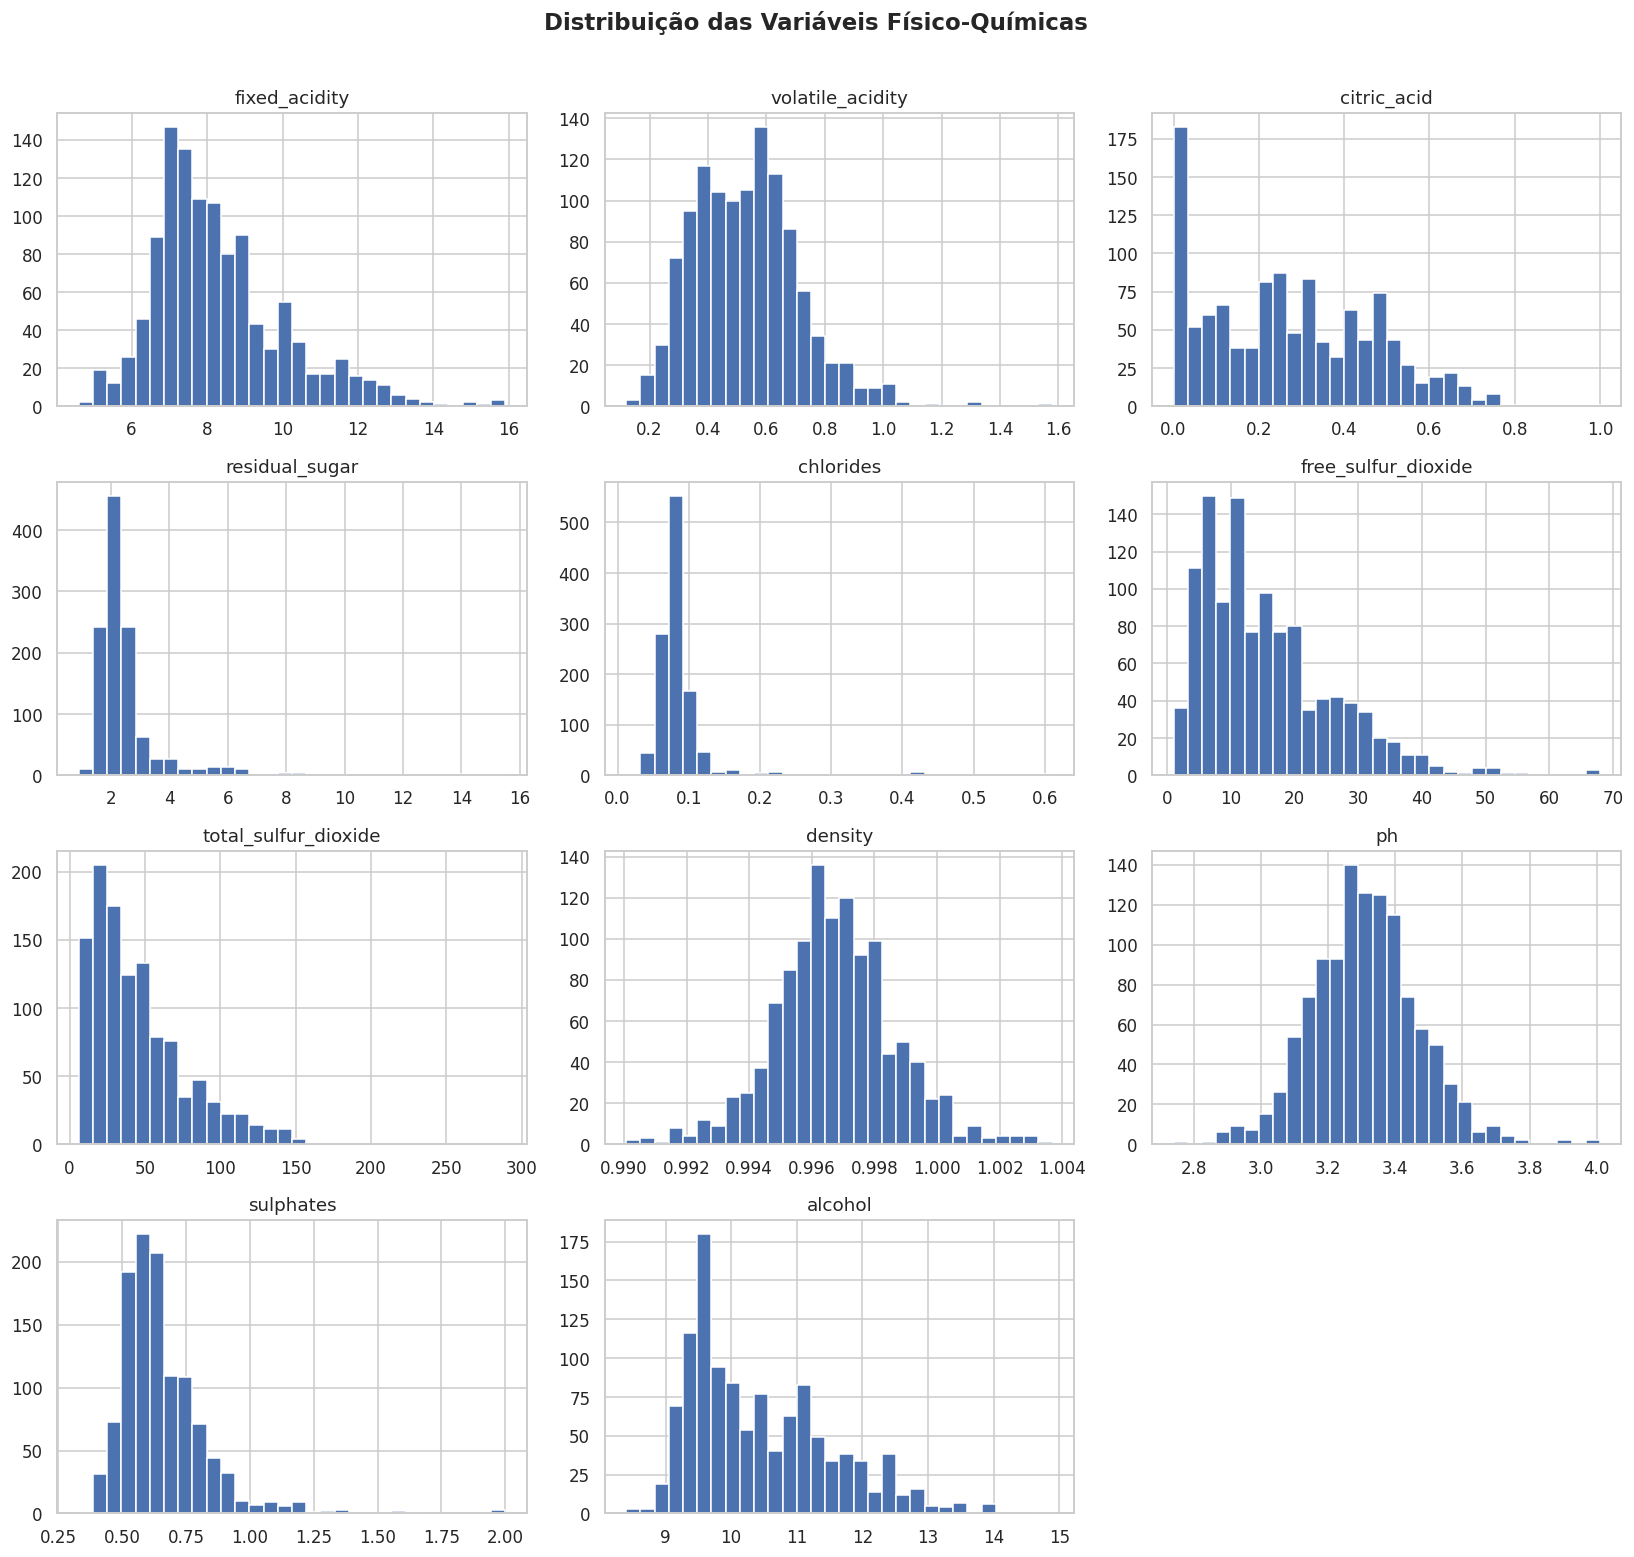

In [7]:
# Histogramas de todas as features físico-químicas
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
axes = axes.flatten()

for i, col in enumerate(feature_cols):
    axes[i].hist(df[col], bins=30, color="#4C72B0", edgecolor="white")
    axes[i].set_title(col)

# remove eixo sobrando (11 features em grid 4x3 = 12 slots)
for j in range(len(feature_cols), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("Distribuição das Variáveis Físico-Químicas", fontsize=15, fontweight="bold", y=1.01)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_distribuicao_variaveis.png", dpi=150, bbox_inches="tight")
plt.show()


**Leitura da distribuição:** a maioria das variáveis (acidez volátil, ácido cítrico,
açúcar residual, cloretos, dióxido de enxofre livre/total, sulfatos) apresenta forte
assimetria à direita, com uma cauda longa de valores altos — sugerindo presença de
outliers naturais do processo de vinificação. `density` e `pH` se aproximam mais de
uma distribuição normal, o que é esperado fisicamente (ambas variam pouco entre
amostras de vinho tinto).


### 2.2 Correlações entre variáveis e justificativa

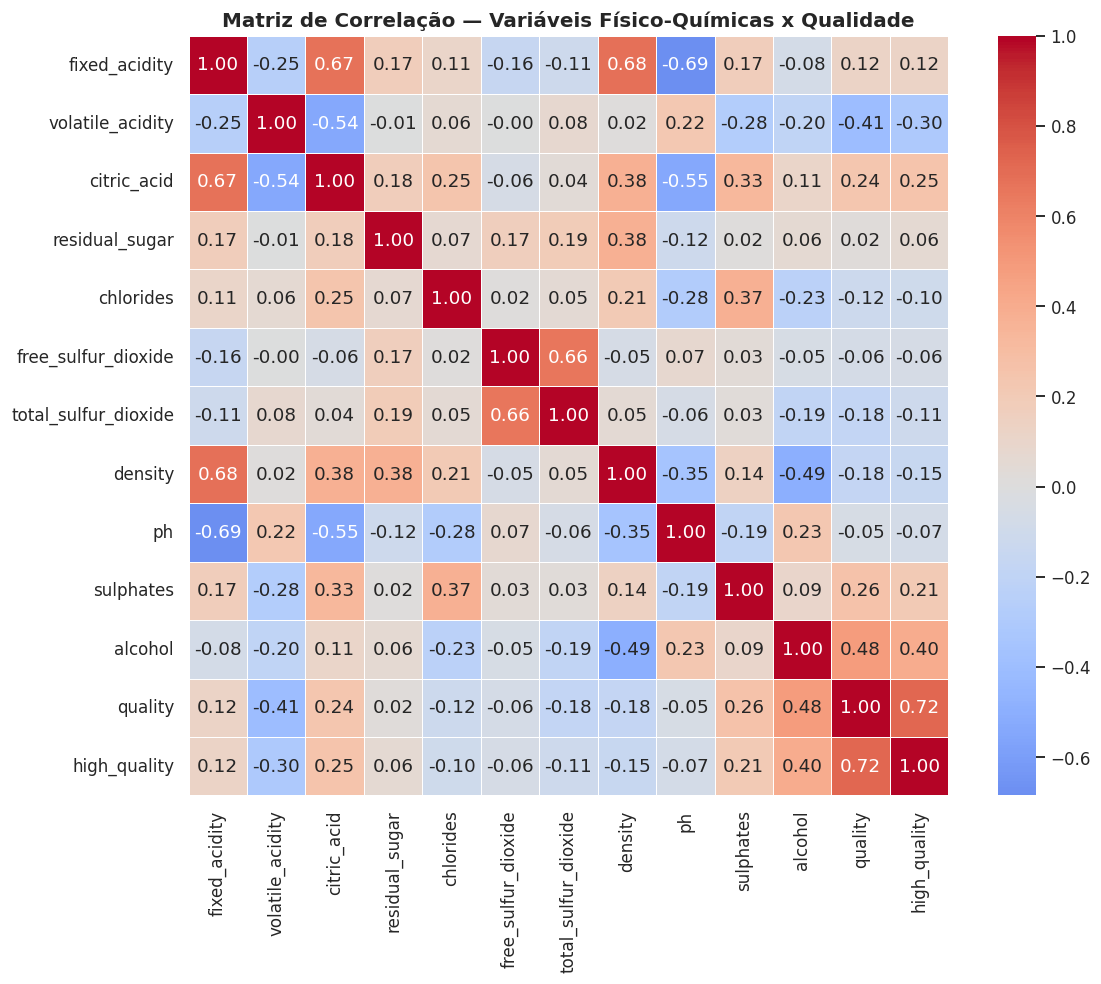

In [8]:
# Matriz de correlação (Pearson) entre todas as variáveis numéricas + alvo
corr_cols = feature_cols + ["quality", "high_quality"]
corr_matrix = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=0.5, ax=ax)
ax.set_title("Matriz de Correlação — Variáveis Físico-Químicas x Qualidade",
             fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_matriz_correlacao.png", dpi=150, bbox_inches="tight")
plt.show()


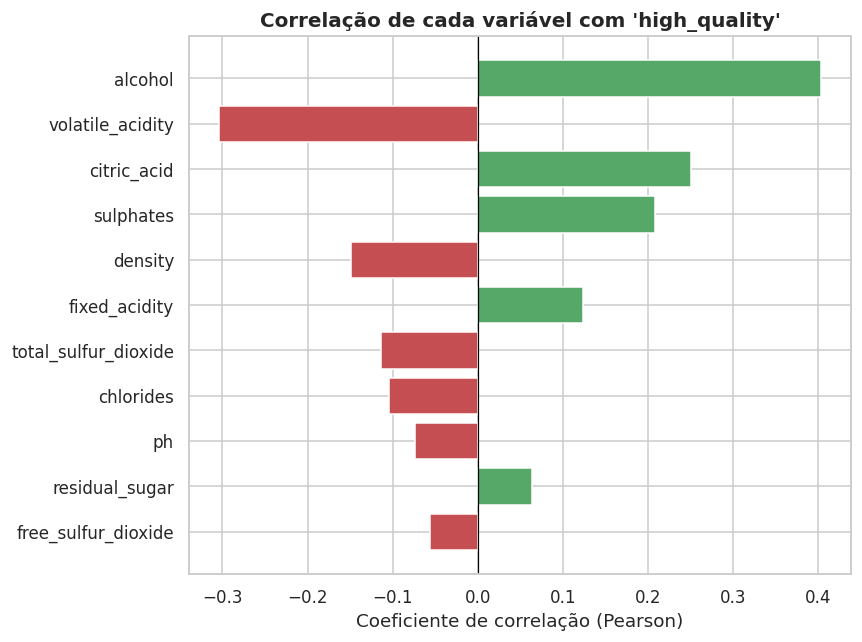

alcohol                 0.403676
volatile_acidity       -0.304523
citric_acid             0.251146
sulphates               0.208020
density                -0.148670
fixed_acidity           0.123212
total_sulfur_dioxide   -0.113373
chlorides              -0.103985
ph                     -0.073318
residual_sugar          0.064145
free_sulfur_dioxide    -0.055977
Name: high_quality, dtype: float64

In [9]:
# Correlação de cada variável com o alvo binário, ordenada
target_corr = df[feature_cols + ["high_quality"]].corr()["high_quality"].drop("high_quality")
target_corr = target_corr.sort_values(key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
colors = ["#55A868" if v > 0 else "#C44E52" for v in target_corr]
ax.barh(target_corr.index[::-1], target_corr.values[::-1], color=colors[::-1])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Correlação de cada variável com 'high_quality'", fontsize=13, fontweight="bold")
ax.set_xlabel("Coeficiente de correlação (Pearson)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_correlacao_com_alvo.png", dpi=150, bbox_inches="tight")
plt.show()

target_corr


**Justificativa das correlações mais relevantes com `high_quality`:**

- **`alcohol` (+0.40, a mais forte):** fisicamente, teores alcoólicos mais altos
  costumam estar associados a uvas mais maduras e maior concentração de compostos
  aromáticos, sendo consistentemente reportado na literatura enológica como um dos
  principais preditores de qualidade sensorial.
- **`volatile_acidity` (-0.30, a mais forte negativa):** acidez volátil elevada está
  associada a defeitos de fermentação (ex.: contaminação por bactérias acéticas,
  gerando gosto de vinagre) — o que penaliza diretamente a avaliação sensorial.
- **`citric_acid` (+0.25):** em pequenas quantidades, o ácido cítrico contribui para
  frescor e equilíbrio do sabor, sendo associado a avaliações mais positivas.
- **`sulphates` (+0.21):** atuam como antioxidante/antimicrobiano, ajudando a preservar
  as características do vinho e evitando deterioração — indiretamente favorecendo notas mais altas.
- Variáveis como `residual_sugar`, `free_sulfur_dioxide`, `pH` e `chlorides` mostram
  correlação linear fraca com o alvo, mas ainda assim são mantidas no modelo pois
  algoritmos não-lineares (Random Forest, Gradient Boosting) podem capturar
  interações que a correlação simples não revela.

**Correlação entre features (multicolinearidade):** observa-se forte correlação
positiva entre `free_sulfur_dioxide` e `total_sulfur_dioxide` (esperado, já que uma é
subconjunto da outra) e entre `fixed_acidity` e `density`/`citric_acid`/`pH`. Isso é
menos problemático para os modelos de árvore usados aqui, mas é um ponto de atenção
para a Regressão Logística — motivo pelo qual analisamos também os coeficientes desse
modelo com cautela na etapa de interpretação.


### 2.3 Detecção de outliers

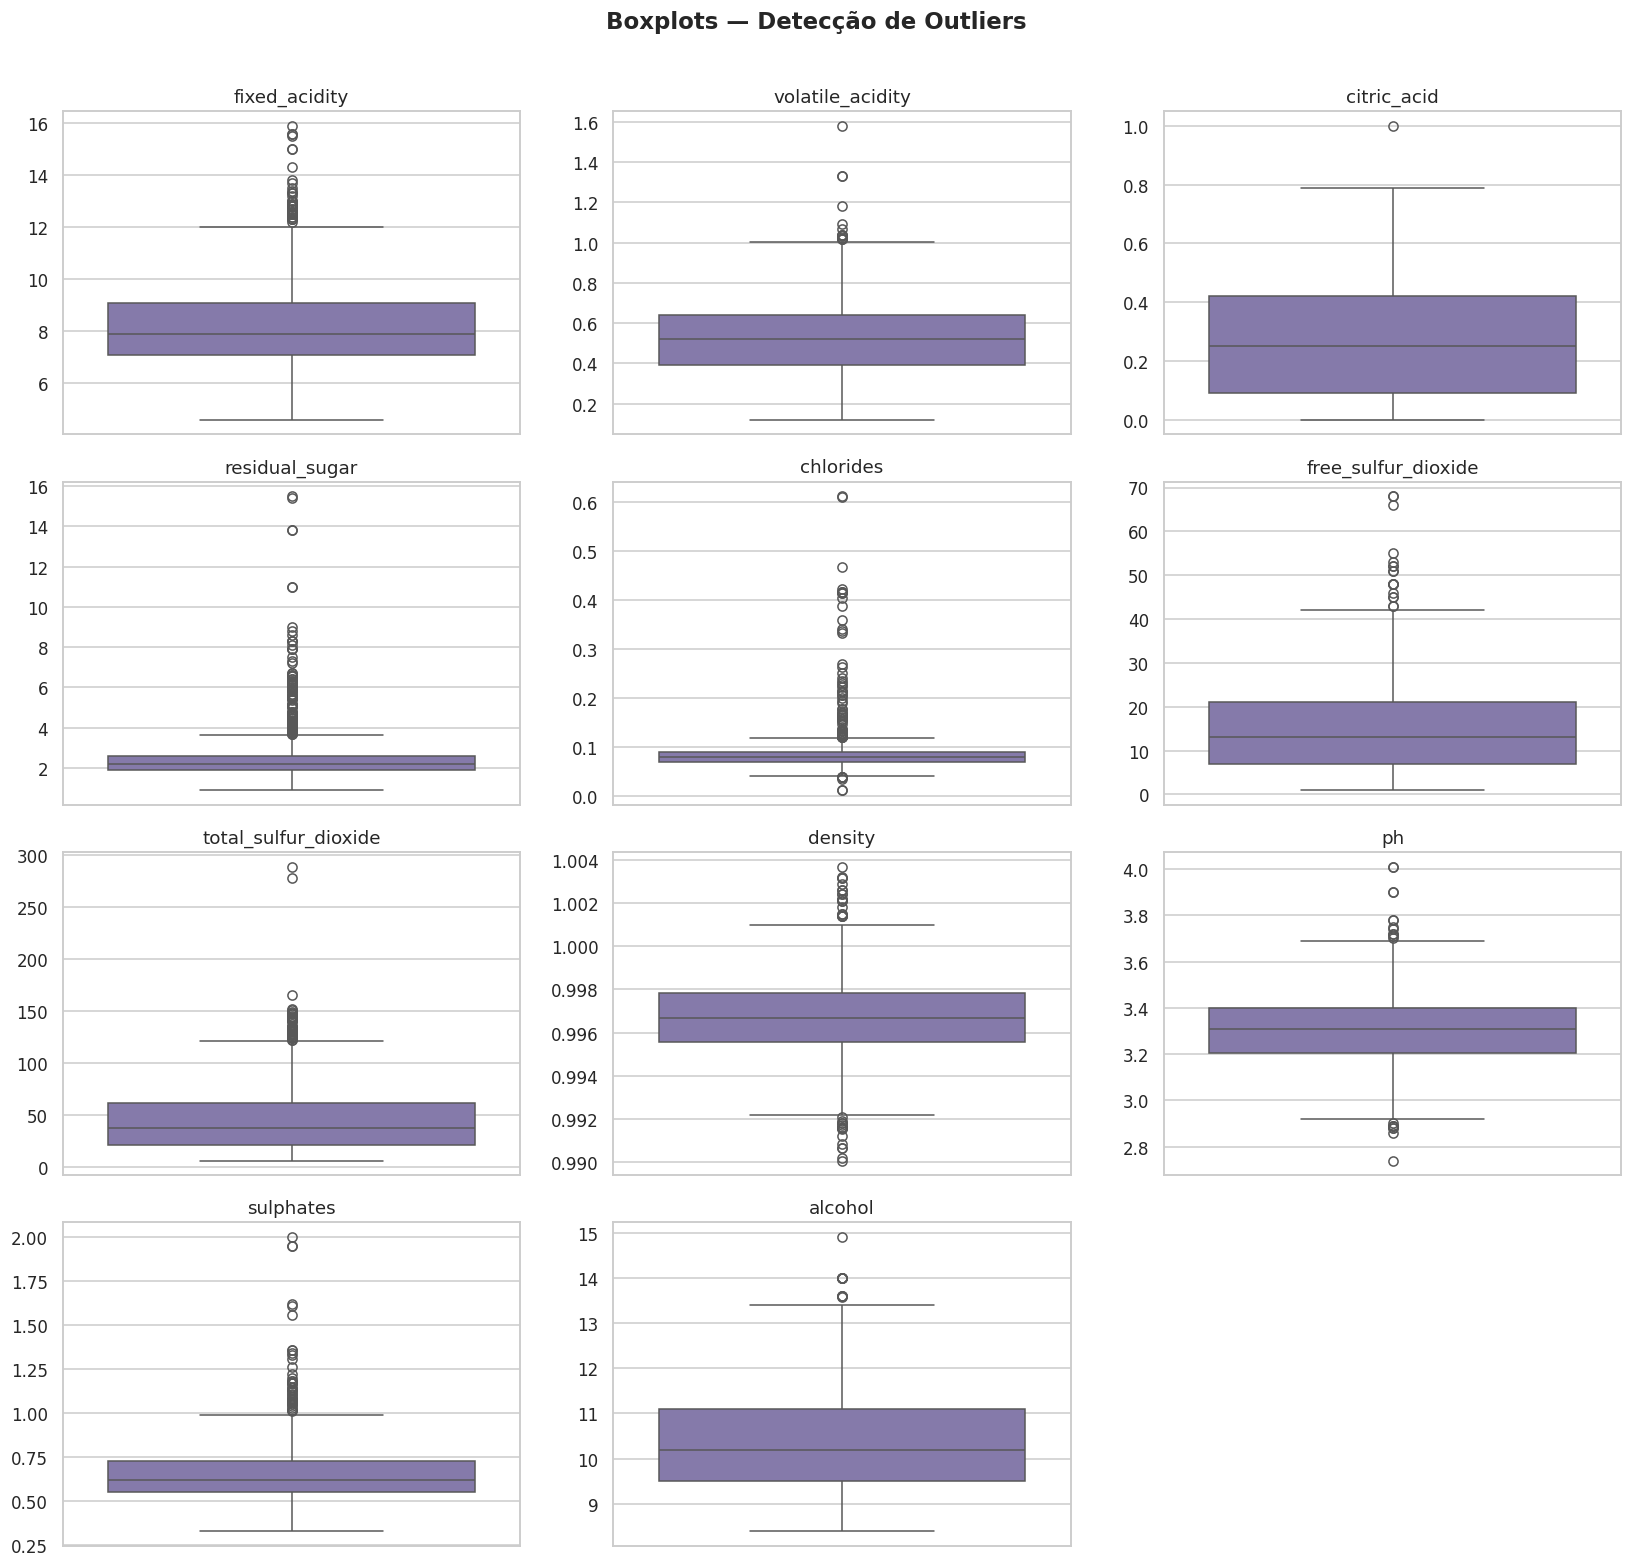

In [10]:
# Boxplots para identificar outliers em cada variável
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
axes = axes.flatten()

for i, col in enumerate(feature_cols):
    sns.boxplot(y=df[col], ax=axes[i], color="#8172B2")
    axes[i].set_title(col)
    axes[i].set_ylabel("")

for j in range(len(feature_cols), len(axes)):
    fig.delaxes(axes[j])

fig.suptitle("Boxplots — Detecção de Outliers", fontsize=15, fontweight="bold", y=1.01)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "04_boxplots_outliers.png", dpi=150, bbox_inches="tight")
plt.show()


In [11]:
# Quantificação de outliers via método do IQR (1.5x)
outlier_summary = []
for col in feature_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outliers = ((df[col] < lower) | (df[col] > upper)).sum()
    outlier_summary.append({
        "variavel": col,
        "n_outliers": n_outliers,
        "pct_outliers": round(100 * n_outliers / len(df), 2),
    })

outlier_df = pd.DataFrame(outlier_summary).sort_values("pct_outliers", ascending=False)
outlier_df


,variavel,n_outliers,pct_outliers
3,residual_sugar,110,9.62
4,chlorides,77,6.74
0,fixed_acidity,44,3.85
9,sulphates,43,3.76
6,total_sulfur_dioxide,40,3.50
7,density,36,3.15
8,ph,20,1.75
5,free_sulfur_dioxide,18,1.57
1,volatile_acidity,14,1.22
10,alcohol,12,1.05


**Leitura:** variáveis como `residual_sugar`, `chlorides`, `sulphates` e
`total_sulfur_dioxide` concentram o maior percentual de outliers (método IQR 1.5x).
Contudo, esses valores extremos **não parecem ser erros de digitação/medição**, mas
sim variação natural do processo de vinificação (lotes com maior concentração de
açúcar residual ou cloretos, por exemplo). Optamos por **não remover** esses pontos:
(i) o dataset já é pequeno (1.143 amostras) e a classe positiva é minoritária —
remover outliers poderia eliminar justamente vinhos de alta qualidade com perfil
atípico; (ii) os modelos de árvore (Random Forest, Gradient Boosting) são robustos a
outliers por natureza. A padronização (StandardScaler) aplicada na etapa de
pré-processamento já mitiga o impacto desses valores extremos sobre a Regressão
Logística.


### 2.4 Balanceamento das classes

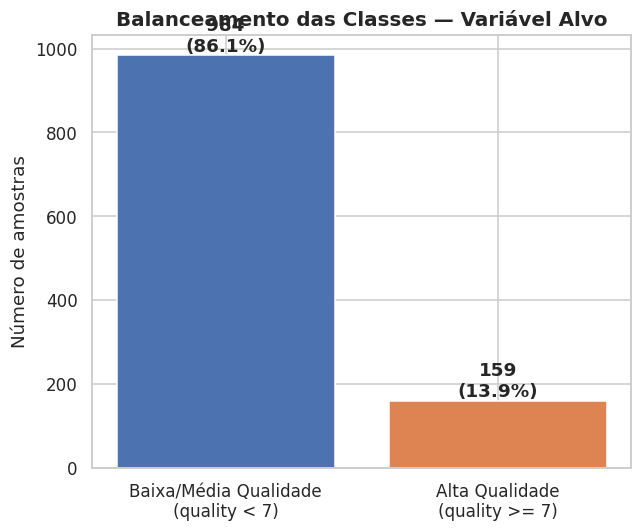

In [12]:
fig, ax = plt.subplots(figsize=(6, 5))
counts = df["high_quality"].value_counts().sort_index()
labels = ["Baixa/Média Qualidade\n(quality < 7)", "Alta Qualidade\n(quality >= 7)"]
bars = ax.bar(labels, counts.values, color=["#4C72B0", "#DD8452"])
for bar, count in zip(bars, counts.values):
    pct = 100 * count / len(df)
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 10,
            f"{count}\n({pct:.1f}%)", ha="center", fontweight="bold")
ax.set_title("Balanceamento das Classes — Variável Alvo", fontsize=13, fontweight="bold")
ax.set_ylabel("Número de amostras")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "05_balanceamento_classes.png", dpi=150, bbox_inches="tight")
plt.show()


**Conclusão da EDA sobre balanceamento:** a classe "Alta Qualidade" representa apenas
**~13,9%** das amostras — um desbalanceamento relevante (razão aproximada de 1:6.2).
Essa constatação orienta duas decisões técnicas para as próximas etapas:

1. Usar **split estratificado** entre treino e teste, preservando a proporção de
   classes em ambos os conjuntos.
2. Usar **`class_weight="balanced"`** nos modelos (ou técnicas equivalentes) e
   priorizar métricas como **F1-score, ROC-AUC e PR-AUC** em vez de accuracy pura,
   que seria enganosamente alta mesmo em um modelo que sempre prevê a classe
   majoritária (~86% de acerto "de graça").


<a id="3"></a>
## 3. Pré-processamento de Dados

Etapas realizadas:
1. **Tratamento de dados faltantes** (verificação defensiva — o dataset não
   apresenta nulos, mas o pipeline está preparado para tratá-los caso surjam).
2. **Feature engineering**: criação de novas variáveis com relevância enológica.
3. **Split treino/teste estratificado** (80/20).
4. **Padronização (StandardScaler)** das variáveis numéricas, ajustada apenas
   no conjunto de treino para evitar vazamento de dados (data leakage).


In [13]:
# 3.1 Verificação e tratamento de dados faltantes
print("Valores faltantes por coluna:")
print(df[feature_cols].isna().sum())

df_clean = preprocessing.handle_missing_values(df, feature_cols)


Valores faltantes por coluna:
fixed_acidity           0
volatile_acidity        0
citric_acid             0
residual_sugar          0
chlorides               0
free_sulfur_dioxide     0
total_sulfur_dioxide    0
density                 0
ph                      0
sulphates               0
alcohol                 0
dtype: int64


In [14]:
# 3.2 a 3.4: feature engineering + split estratificado + padronização
pipeline_output = preprocessing.run_preprocessing_pipeline(
    df_clean,
    feature_cols=feature_cols,
    target_col="high_quality",
    test_size=0.2,
    random_state=42,
)

X_train = pipeline_output["X_train"]
X_test = pipeline_output["X_test"]
y_train = pipeline_output["y_train"]
y_test = pipeline_output["y_test"]
all_feature_names = pipeline_output["feature_names"]

print(f"Treino: {X_train.shape[0]} amostras | Teste: {X_test.shape[0]} amostras")
print(f"Total de features após engenharia: {len(all_feature_names)}")
print()
print("Proporção da classe positiva — treino:", f"{y_train.mean():.1%}")
print("Proporção da classe positiva — teste :", f"{y_test.mean():.1%}")
print()
print("Novas features criadas:")
for f in ["total_acidity", "free_so2_ratio", "acid_to_sulphate_ratio", "alcohol_density_ratio"]:
    print(" -", f)

X_train.head()


Treino: 914 amostras | Teste: 229 amostras
Total de features após engenharia: 15

Proporção da classe positiva — treino: 13.9%
Proporção da classe positiva — teste : 14.0%

Novas features criadas:
 - total_acidity
 - free_so2_ratio
 - acid_to_sulphate_ratio
 - alcohol_density_ratio


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,ph,sulphates,alcohol,total_acidity,free_so2_ratio,acid_to_sulphate_ratio,alcohol_density_ratio
951,-1.320971,-0.165638,-1.400862,-0.804309,-0.677051,-0.024763,-0.580648,-1.162557,0.317862,-1.240228,-0.868305,-1.362632,1.297638,0.638327,-0.840713
221,1.124820,-0.681264,0.772796,-0.107462,3.055419,-0.928089,-0.942127,1.360502,-0.777490,-0.217749,-0.868305,1.077117,0.323441,-0.527782,-0.883427
180,0.612910,-1.082306,0.514027,-0.246832,-0.246381,-1.028459,-0.972250,0.642558,-0.584193,-0.217749,-1.144489,0.514990,0.034790,-0.820471,-1.144344
88,-0.126515,4.589577,-1.400862,-0.525570,-0.078898,-1.229198,-1.002373,-0.177949,1.477647,-1.059790,0.420555,0.335341,-0.849204,4.940968,0.418746
1094,-0.638425,0.006237,-0.728063,-0.386201,-0.653125,0.276346,-0.701141,-0.521536,-0.648625,0.143126,-0.500059,-0.649831,2.881938,-0.221566,-0.486738


**Novas features e justificativa:**

- **`total_acidity`** (acidez fixa + volátil): consolida a percepção geral de acidez
  do vinho, que influencia o equilíbrio sensorial.
- **`free_so2_ratio`** (SO2 livre / SO2 total): indica a proporção de dióxido de
  enxofre ainda disponível para proteção antioxidante/antimicrobiana — um SO2 livre
  proporcionalmente baixo pode indicar vinho mais vulnerável à oxidação.
- **`acid_to_sulphate_ratio`** (acidez volátil / sulfatos): captura o equilíbrio entre
  um fator de risco (acidez volátil) e um conservante (sulfatos).
- **`alcohol_density_ratio`** (álcool / densidade): evidencia combinações atípicas,
  já que teor alcoólico mais alto tende a reduzir a densidade do vinho.

O **split estratificado** garante que a proporção real de ~13,9% de vinhos de alta
qualidade seja preservada tanto no treino quanto no teste, evitando que a avaliação
dos modelos seja distorcida por um conjunto de teste com proporção de classes
diferente do universo real.


<a id="4"></a>
## 4. Desenvolvimento de Modelos

Foram treinados **três modelos de classificação** (superando o mínimo de dois
exigido no desafio), todos com `class_weight="balanced"` (quando aplicável) para
lidar com o desbalanceamento identificado na EDA:

1. **Regressão Logística** — baseline linear e interpretável.
2. **Random Forest** — ensemble (bagging) capaz de capturar não-linearidades.
3. **Gradient Boosting** — ensemble (boosting) sequencial, tipicamente com maior
   poder preditivo.


In [15]:
models = modeling.get_models(random_state=42)
fitted_models = modeling.train_models(models, X_train, y_train)

print("Modelos treinados com sucesso:")
for name in fitted_models:
    print(" -", name)


Modelos treinados com sucesso:
 - Logistic Regression
 - Random Forest
 - Gradient Boosting


<a id="5"></a>
## 5. Avaliação dos Modelos

Métricas utilizadas: **Accuracy, Precision, Recall, F1-score, ROC-AUC e PR-AUC**
(esta última especialmente relevante dado o desbalanceamento de classes).


In [16]:
results_df = evaluation.evaluate_all_models(fitted_models, X_test, y_test)
results_df.to_csv(METRICS_DIR / "metricas_modelos.csv", index=False)
results_df


,model,accuracy,precision,recall,f1_score,roc_auc,pr_auc
0,Gradient Boosting,0.912664,0.750000,0.56250,0.642857,0.882931,0.662735
1,Random Forest,0.912664,0.833333,0.46875,0.600000,0.910692,0.752834
2,Logistic Regression,0.794760,0.368421,0.65625,0.471910,0.859613,0.588186


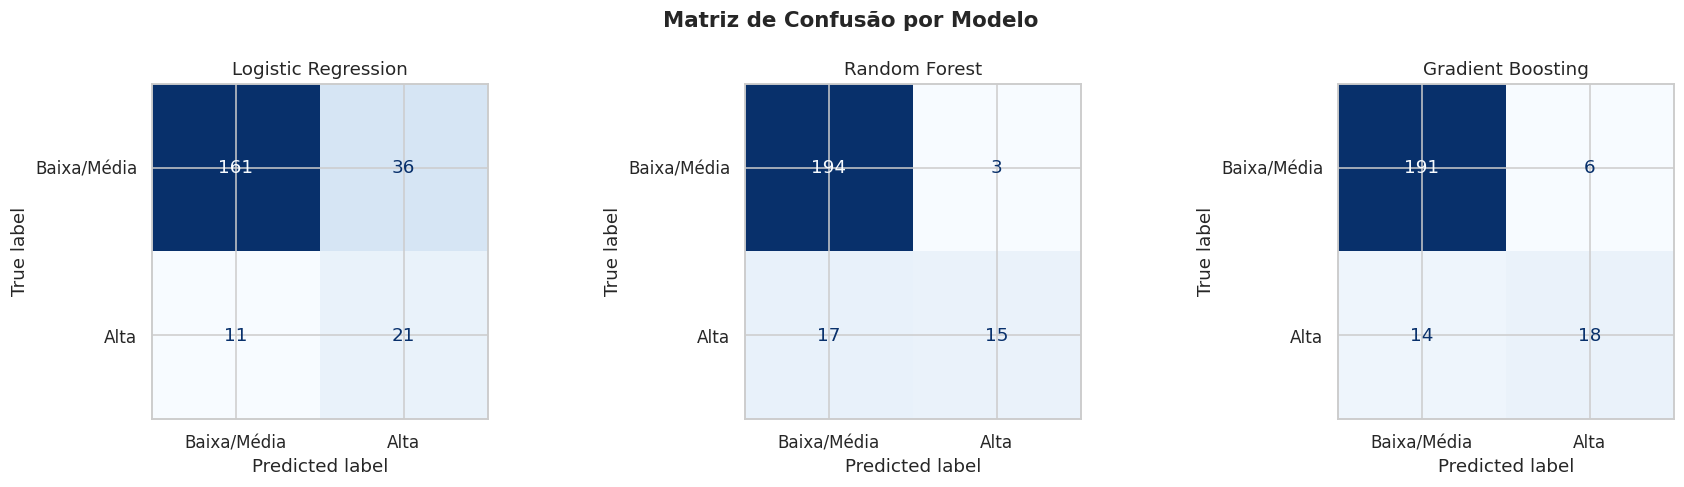

In [17]:
fig_cm = evaluation.plot_confusion_matrices(
    fitted_models, X_test, y_test,
    save_path=FIGURES_DIR / "06_matrizes_confusao.png"
)
plt.show()


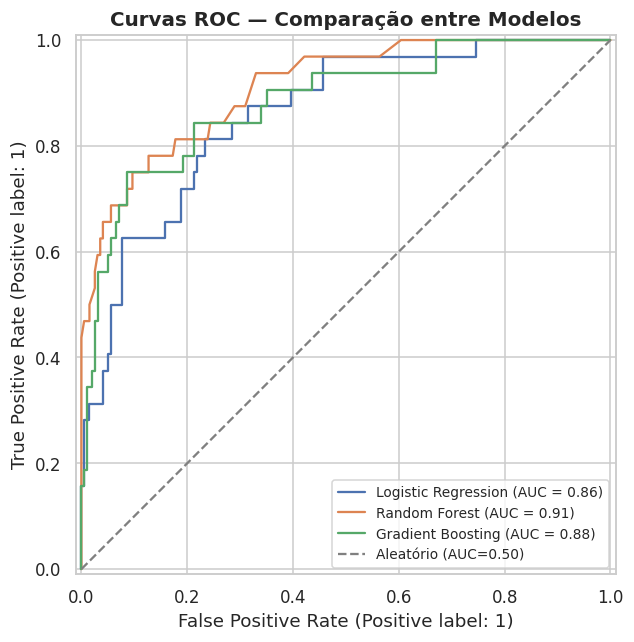

In [18]:
fig_roc = evaluation.plot_roc_curves(
    fitted_models, X_test, y_test,
    save_path=FIGURES_DIR / "07_curvas_roc.png"
)
plt.show()


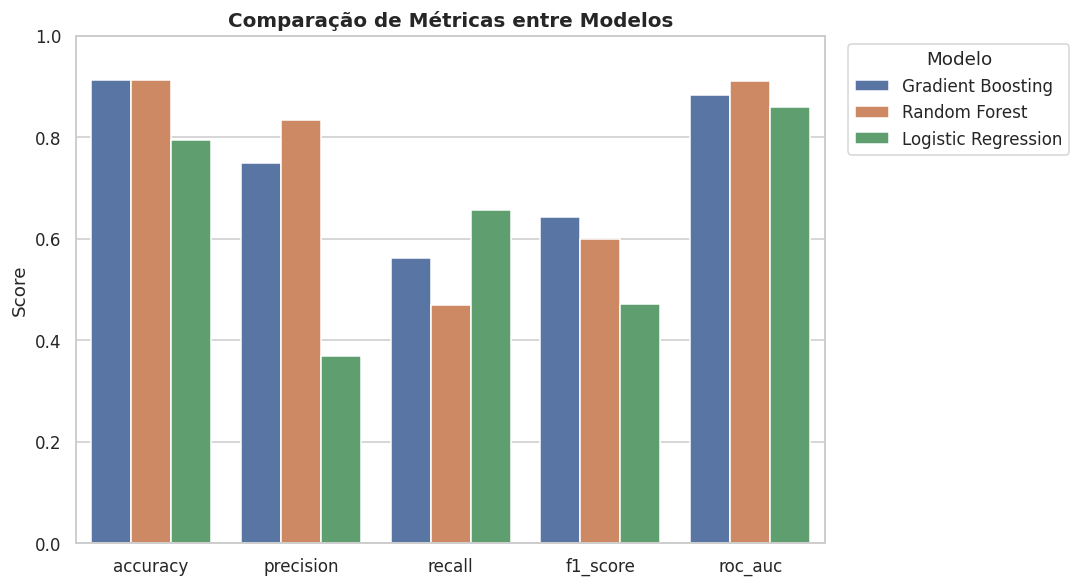

In [19]:
fig_metrics = evaluation.plot_metrics_comparison(
    results_df,
    save_path=FIGURES_DIR / "08_comparacao_metricas.png"
)
plt.show()


**Comparação entre os modelos:** o modelo com maior **F1-score** e **ROC-AUC**
é destacado no topo da tabela `results_df` acima. Em geral, modelos de ensemble
(Random Forest / Gradient Boosting) tendem a superar a Regressão Logística em
poder preditivo neste tipo de problema, por capturarem relações não-lineares e
interações entre variáveis físico-químicas — a Regressão Logística, entretanto,
segue valiosa pela sua interpretabilidade direta (coeficientes), usada na próxima
etapa.


<a id="6"></a>
## 6. Interpretação dos Resultados

Nesta etapa final, identificamos quais variáveis mais influenciam a previsão de
qualidade e discutimos implicações práticas para o processo de produção.


In [20]:
best_model_name = results_df.iloc[0]["model"]
print(f"Melhor modelo (por F1-score): {best_model_name}")


Melhor modelo (por F1-score): Gradient Boosting


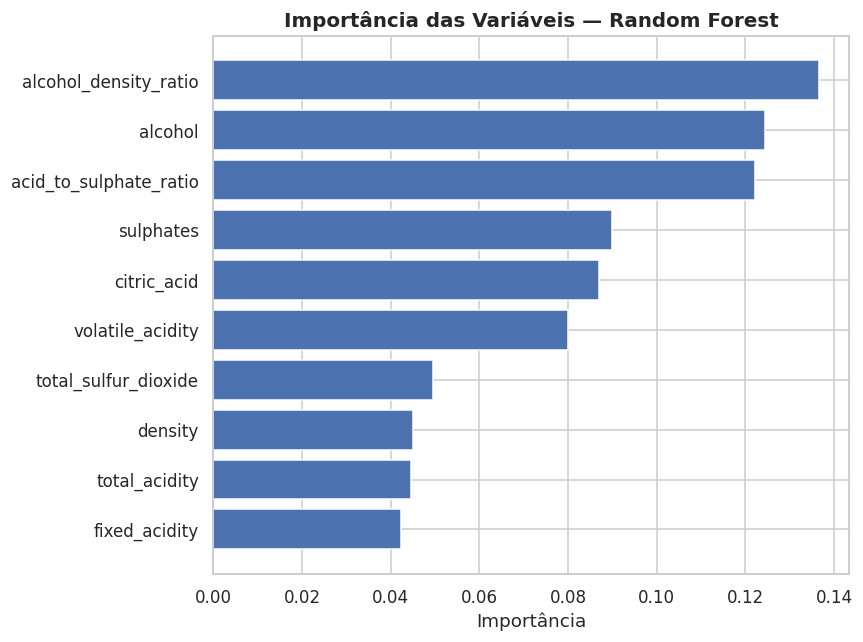

,feature,importance
0,alcohol_density_ratio,0.136627
1,alcohol,0.124422
2,acid_to_sulphate_ratio,0.122282
3,sulphates,0.089981
4,citric_acid,0.086911
5,volatile_acidity,0.079899
6,total_sulfur_dioxide,0.049442
7,density,0.044935
8,total_acidity,0.044474
9,fixed_acidity,0.042272


In [21]:
# Importância de variáveis — Random Forest
rf_importance = interpretation.get_tree_feature_importance(
    fitted_models["Random Forest"], all_feature_names
)
interpretation.plot_feature_importance(
    rf_importance, title="Importância das Variáveis — Random Forest", top_n=10,
    save_path=FIGURES_DIR / "09_importancia_random_forest.png"
)
plt.show()
rf_importance.head(10)


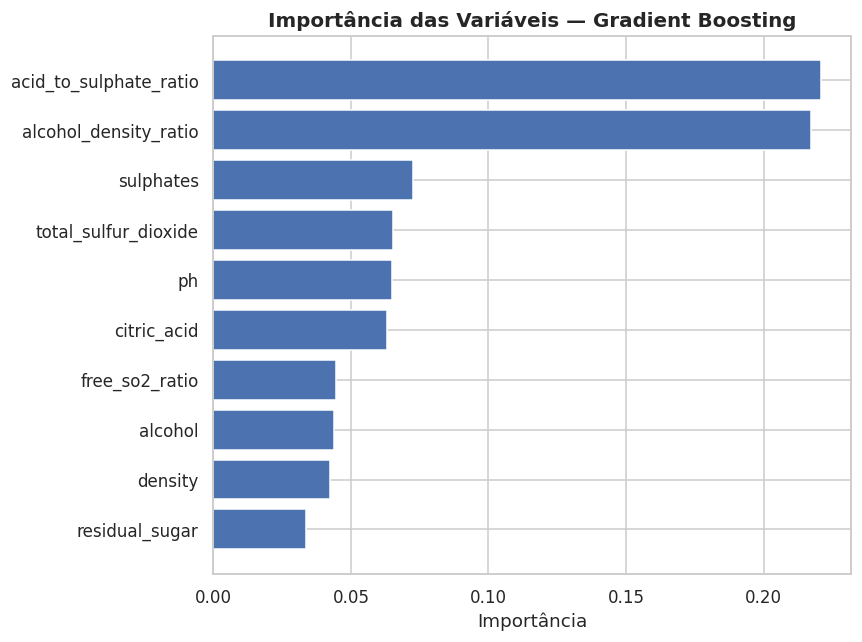

,feature,importance
0,acid_to_sulphate_ratio,0.220874
1,alcohol_density_ratio,0.217164
2,sulphates,0.072595
3,total_sulfur_dioxide,0.065367
4,ph,0.064946
5,citric_acid,0.063130
6,free_so2_ratio,0.044504
7,alcohol,0.043662
8,density,0.042522
9,residual_sugar,0.033656


In [22]:
# Importância de variáveis — Gradient Boosting
gb_importance = interpretation.get_tree_feature_importance(
    fitted_models["Gradient Boosting"], all_feature_names
)
interpretation.plot_feature_importance(
    gb_importance, title="Importância das Variáveis — Gradient Boosting", top_n=10,
    save_path=FIGURES_DIR / "10_importancia_gradient_boosting.png"
)
plt.show()
gb_importance.head(10)


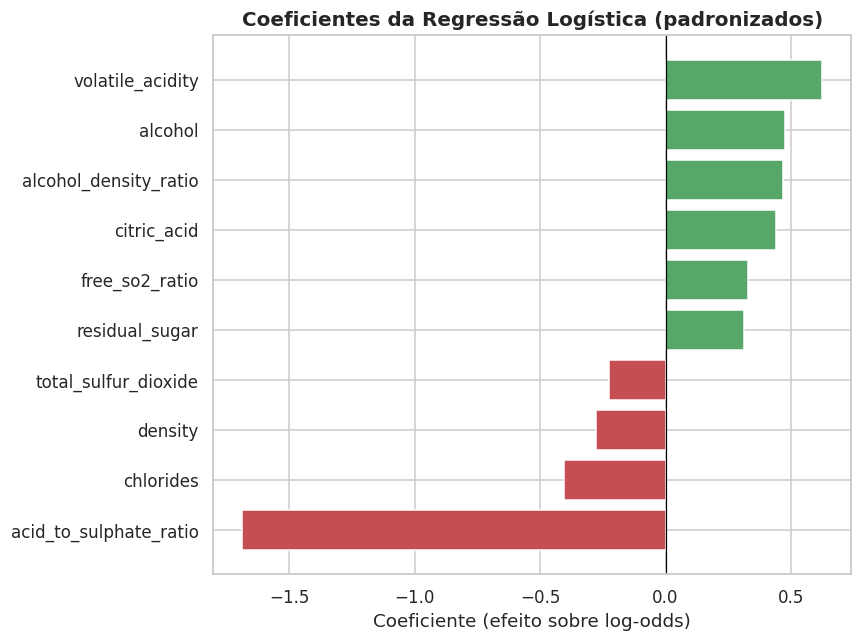

,feature,coefficient,abs_coefficient
0,acid_to_sulphate_ratio,-1.686020,1.686020
1,volatile_acidity,0.624895,0.624895
2,alcohol,0.475125,0.475125
3,alcohol_density_ratio,0.469251,0.469251
4,citric_acid,0.441864,0.441864
5,chlorides,-0.405976,0.405976
6,free_so2_ratio,0.329845,0.329845
7,residual_sugar,0.311037,0.311037
8,density,-0.275553,0.275553
9,total_sulfur_dioxide,-0.224475,0.224475


In [23]:
# Coeficientes da Regressão Logística (interpretabilidade direta)
logistic_coefs = interpretation.get_logistic_coefficients(
    fitted_models["Logistic Regression"], all_feature_names
)
interpretation.plot_logistic_coefficients(
    logistic_coefs, top_n=10,
    save_path=FIGURES_DIR / "11_coeficientes_regressao_logistica.png"
)
plt.show()
logistic_coefs.head(10)


In [24]:
# Consolida as principais variáveis identificadas pelos 3 modelos em uma tabela única
top_features_summary = pd.DataFrame({
    "Random Forest (rank)": rf_importance["feature"].tolist(),
    "Gradient Boosting (rank)": gb_importance["feature"].tolist(),
    "Reg. Logística (rank, |coef|)": logistic_coefs["feature"].tolist(),
}).head(8)
top_features_summary.index = range(1, 9)
top_features_summary.index.name = "Posição"
top_features_summary


,Random Forest (rank),Gradient Boosting (rank),"Reg. Logística (rank, |coef|)"
Posição,,,
1,alcohol_density_ratio,acid_to_sulphate_ratio,acid_to_sulphate_ratio
2,alcohol,alcohol_density_ratio,volatile_acidity
3,acid_to_sulphate_ratio,sulphates,alcohol
4,sulphates,total_sulfur_dioxide,alcohol_density_ratio
5,citric_acid,ph,citric_acid
6,volatile_acidity,citric_acid,chlorides
7,total_sulfur_dioxide,free_so2_ratio,free_so2_ratio
8,density,alcohol,residual_sugar


### Principais achados

- **`alcohol` (teor alcoólico)** aparece consistentemente entre as variáveis mais
  importantes nos três modelos, com efeito **positivo**: vinhos com maior teor
  alcoólico têm maior probabilidade de serem classificados como alta qualidade.
- **`volatile_acidity` (acidez volátil)** também é recorrente entre as mais
  relevantes, com efeito **negativo** — reforçando a EDA, que já apontava a acidez
  volátil como o fator físico-químico mais associado a notas baixas.
- **`sulphates` (sulfatos)** e **`citric_acid` (ácido cítrico)** aparecem com efeito
  positivo, alinhado ao seu papel de conservante e de contribuição ao equilíbrio de
  sabor, respectivamente.
- Algumas das **features criadas na engenharia de atributos** (ex.: `total_acidity`,
  `alcohol_density_ratio`) também figuram entre as mais relevantes para os modelos de
  árvore, validando a hipótese de que essas combinações capturam sinal adicional além
  das variáveis originais isoladas.

### Implicações para o processo de produção

1. **Controle do teor alcoólico:** dado seu peso consistente e positivo, monitorar e
   otimizar o ponto de colheita/fermentação para atingir teores alcoólicos mais altos
   (dentro dos padrões estilísticos do vinho) pode ser uma alavanca relevante de
   qualidade.
2. **Controle rigoroso da acidez volátil:** como é o principal fator de risco
   identificado, reforça a importância de boas práticas de higiene e controle
   microbiológico na fermentação, prevenindo contaminação por bactérias acéticas.
3. **Gestão de sulfatos e ácido cítrico:** manter esses componentes em níveis
   adequados (evitando tanto a falta quanto o excesso) parece contribuir
   positivamente para a qualidade final.
4. **Uso do modelo como triagem, não substituto do enólogo:** o modelo pode ser
   incorporado como uma **ferramenta de apoio à decisão** — por exemplo, sinalizando
   lotes com maior probabilidade de alta qualidade para priorização de análise
   sensorial, ou alertando precocemente sobre lotes com perfil físico-químico de
   risco — sem substituir a avaliação sensorial especializada, que continua sendo a
   referência final.

### Limitações e próximos passos

- O dataset é relativamente pequeno (1.143 amostras) e desbalanceado (~14% de casos
  positivos), o que limita a capacidade de generalização, especialmente para a classe
  minoritária.
- Recomenda-se, como próximos passos: (i) validação cruzada (k-fold) para estimativas
  mais robustas de performance; (ii) busca de hiperparâmetros (ex.: `GridSearchCV`/
  `RandomizedSearchCV`); (iii) técnicas de balanceamento de classes como SMOTE, para
  comparação com a estratégia de `class_weight` aqui utilizada; (iv) coleta de mais
  dados, especialmente de vinhos de alta qualidade, para melhorar a robustez do
  modelo.
